# Perceptron from Scratch Using NumPy

## Introduction

A perceptron is one of the simplest artificial neural network models. It is a binary linear classifier that learns to classify input data by adjusting its weights and bias based on prediction errors.

The perceptron is a fundamental building block for understanding more advanced neural network architectures, including Multilayer Perceptrons (MLPs), Convolutional Neural Networks (CNNs), and Transformer-based models.

In this notebook, we will implement a perceptron entirely from scratch using Python and NumPy, without relying on machine learning libraries such as Scikit-learn or deep learning frameworks such as PyTorch.

<div align="center">
  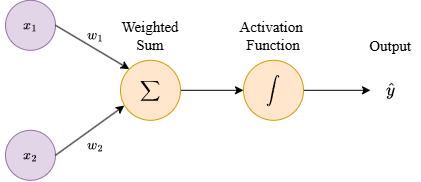
</div>

## Objectives

By the end of this notebook, we will be able to:

* Understand the mathematical foundations of a perceptron.
* Explain weights, bias, weighted sums, and activation functions.
* Implement the perceptron learning algorithm from scratch.
* Train the model using a simple binary classification dataset.
* Evaluate its predictions and visualize its learning process.
* Understand why a single perceptron cannot solve non-linearly separable problems such as XOR.

## Implementation Workflow

* Understand the mathematical model.
* Prepare the dataset.
* Implement the perceptron.
* Train the model.
* Evaluate predictions.
* Visualize the learning process.
* Experiment with OR logical operation.
* Discuss limitations and conclusions.

# Dataset Preparation

We will train the perceptron to learn the logical OR operation using four input combinations.

The OR gate produces an output of 1 when at least one input is 1. Otherwise, its output is 0.

| Input $x_1$ | Input $x_2$ | Expected output $y$ |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 1 |

Each input contains two features, so the perceptron will learn two weights and one bias.

This dataset is linearly separable, making it suitable for demonstrating the classical perceptron learning algorithm.

In [1]:
import numpy as np
# Implementing OR using Perceptron


X = np.array([
    [0,0],
    [0,1],
    [1,0],
    [1,1]
], dtype = float)

y = np.array([0,1,1,1])

print("Input data:\n", X)
print("Expected outputs:", y)

Input data:
 [[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
Expected outputs: [0 1 1 1]


# Mathematical Foundations

## 1. Architecture of a Perceptron

A perceptron receives one or more input features, multiplies each feature by a corresponding weight, adds a bias, and passes the result through an activation function.

For two input features, the architecture can be represented as:

$$
x_1, x_2
\longrightarrow
\text{Weighted Sum}
\longrightarrow
\text{Activation}
\longrightarrow
\hat{y}
$$

The weighted sum is calculated as:

$$
z = w_1x_1 + w_2x_2 + b
$$

More generally, for $n$ input features:

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$


**Intuition:** The weights determine how strongly the individual input features influence the output. The bias shifts the decision boundary.

## 2. Step Activation Function

The perceptron uses a step activation function to convert the weighted sum into a binary prediction.

$$
\hat{y} =
\begin{cases}
1, & z > 0 \\
0, & z \leq 0
\end{cases}
$$

Here, $\hat{y}$ represents the predicted class.

If the weighted sum is positive, the model predicts class 1. Otherwise, it predicts class 0.

The activation function therefore converts a continuous numerical value into a binary output.

**Note:** The classical perceptron uses a step activation function to produce binary predictions. Multilayer neural networks commonly use differentiable activation functions, such as ReLU or sigmoid, to support gradient-based training through backpropagation.

## 3. Error Calculation

After producing a prediction, the perceptron compares it with the expected output.

The prediction error is calculated as:

$$
e = y - \hat{y}
$$

where:

- $y$ is the expected output.
- $\hat{y}$ is the predicted output.
- $e$ is the prediction error.

An error of zero indicates a correct prediction. A nonzero error indicates a misclassification. The perceptron uses this error to determine how its parameters should change.

## 4. Perceptron Learning Rule

The perceptron learns by updating its weights and bias when a training example is misclassified.

The weight update rule is:

$$
w_i^{\text{new}}
=
w_i^{\text{old}} + \eta e x_i
$$

The bias update rule is:

$$
b^{\text{new}}
=
b^{\text{old}} + \eta e
$$

where:

- $\eta$ is the learning rate.
- $e$ is the prediction error.
- $x_i$ is the corresponding input feature.

The learning rate controls the magnitude of each update.

#### Example

Suppose:

$$
\mathbf{x} = [1,0]
$$

$$
\mathbf{w} = [0.2,-0.1]
$$

$$
b = -0.3
$$

$$
y = 1,\qquad \eta = 0.1
$$

First, calculate the weighted sum:

$$
z = (0.2)(1) + (-0.1)(0) - 0.3
$$

$$
z = -0.1
$$

Since $z \leq 0$, the predicted output is:

$$
\hat{y} = 0
$$

The prediction error is:

$$
e = 1 - 0 = 1
$$

Update the first weight:

$$
w_1^{\text{new}} = 0.2 + (0.1)(1)(1)
$$

$$
w_1^{\text{new}} = 0.3
$$

Update the second weight:

$$
w_2^{\text{new}} = -0.1 + (0.1)(1)(0)
$$

$$
w_2^{\text{new}} = -0.1
$$

Update the bias:

$$
b^{\text{new}} = -0.3 + (0.1)(1)
$$

$$
b^{\text{new}} = -0.2
$$

The updated parameters are:

$$
\mathbf{w} = [0.3,-0.1]
$$

$$
b = -0.2
$$

For the same input, the updated weighted sum becomes:

$$
z = (0.3)(1) + (-0.1)(0) - 0.2 = 0.1
$$

Therefore, the updated prediction is:

$$
\hat{y} = 1
$$

The perceptron has corrected its prediction by updating its weights and bias.

**Key observation:** The error is calculated from the current prediction and target. We use it to update the weights and bias; we do not directly update the error itself.

# Implementing the Perceptron from Scratch

We will implement a `Perceptron` class containing five main components.

1. **Initialization:** Store the learning rate and number of training epochs.
2. **Activation:** Convert the weighted sum into a binary prediction.
3. **Prediction:** Calculate the weighted sum and apply the activation function.
4. **Training:** Calculate errors and update weights and bias.
5. **Inference:** Predict the outputs for a collection of input examples.

The model will initially set all weights and the bias to zero.

During training, it will process each example, calculate its prediction, determine the error, and update the parameters.

One epoch means processing the entire training dataset once.

The training process stops either when all training examples are classified correctly or when the maximum number of epochs has been reached.

In [2]:
import numpy as np


class Perceptron:

    def __init__(self, learning_rate=0.1, epochs=20):
        self.learning_rate = learning_rate
        self.epochs = epochs

        self.weights = None
        self.bias = None

        self.errors_per_epoch = []

    # Activation Function
    def activation(self, z):
        return 1 if z > 0 else 0

    # Prediction
    def predict_single(self, x):
        z = np.dot(x, self.weights) + self.bias
        return self.activation(z)

    # Perceptron Learning Rule
    def fit(self, X, y):

        # Initialize weights and bias
        n_features = X.shape[1]

        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for epoch in range(self.epochs):

            errors = 0

            for xi, target in zip(X, y):

                # Forward pass
                prediction = self.predict_single(xi)

                # Calculate error
                error = target - prediction

                # Update weights and bias
                self.weights += (
                    self.learning_rate * error * xi
                )

                self.bias += self.learning_rate * error

                if error != 0:
                    errors += 1

            self.errors_per_epoch.append(errors)

            print(
                f"Epoch {epoch + 1:02d} | "
                f"Errors: {errors} | "
                f"Weights: {self.weights} | "
                f"Bias: {self.bias:.2f}"
            )

            # Stop when all training examples are classified correctly
            if errors == 0:
                print("Training converged!")
                break

        return self

    def predict(self, X):
        return np.array([
            self.predict_single(xi)
            for xi in X
        ])

In [3]:
# Training the model

model = Perceptron(
    learning_rate=0.1,
    epochs=20
)

_ = model.fit(X, y)

Epoch 01 | Errors: 1 | Weights: [0.  0.1] | Bias: 0.10
Epoch 02 | Errors: 2 | Weights: [0.1 0.1] | Bias: 0.10
Epoch 03 | Errors: 1 | Weights: [0.1 0.1] | Bias: 0.00
Epoch 04 | Errors: 0 | Weights: [0.1 0.1] | Bias: 0.00
Training converged!


In [4]:
# Model Prediction

predictions = model.predict(X)

print("\nFinal Results")
print("-" * 40)

for inputs, actual, predicted in zip(
    X, y, predictions
):
    print(
        f"Input: {inputs.astype(int)} | "
        f"Actual: {actual} | "
        f"Predicted: {predicted}"
    )

accuracy = np.mean(predictions == y) * 100

print(f"\nTraining accuracy: {accuracy:.2f}%")


Final Results
----------------------------------------
Input: [0 0] | Actual: 0 | Predicted: 0
Input: [0 1] | Actual: 1 | Predicted: 1
Input: [1 0] | Actual: 1 | Predicted: 1
Input: [1 1] | Actual: 1 | Predicted: 1

Training accuracy: 100.00%


# Visualizing the Learning Process

We can visualize the number of misclassified examples at the end of each epoch.

The horizontal axis represents the training epoch, while the vertical axis represents the number of mistakes made during that epoch.

The learning curve helps us observe how the model approaches a solution.

For a linearly separable dataset, the classical perceptron learning algorithm converges after a finite number of updates under its standard assumptions. However, this guarantee does not apply to non-linearly separable datasets such as XOR.

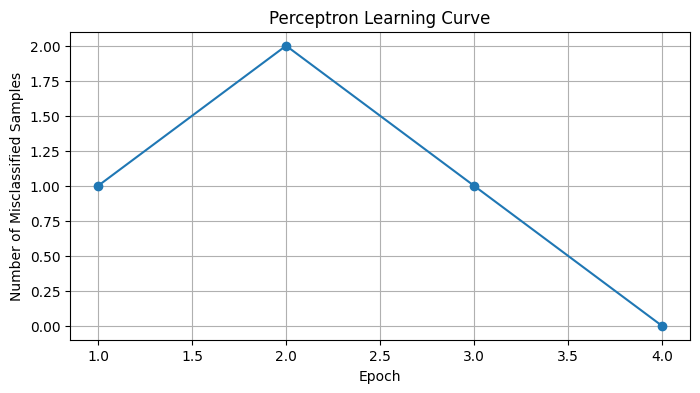

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(model.errors_per_epoch) + 1),
    model.errors_per_epoch,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Number of Misclassified Samples")
plt.title("Perceptron Learning Curve")

plt.grid(True)
plt.show()

# Points to Note

* Similar to OR implementation using Perceptron, we can also implement AND, NOT as well
* However, XOR Gate cannot be implemented using classical Perceptron as XOR is not linearly separable like AND, OR and NOT Gates.